# 50 · 이미지와 텍스트를 정렬하고 설명 생성하기

빨간 원을 보고 `red round`라고 설명합니다. 이미지 화소와 token ID는 서로 다른 입력이지만, 같은 장면을 나타낼 수 있습니다. 먼저 두 표현을 가까이 학습하고, 다음에는 **이미지 조건에서 설명 token을 실제로 생성**합니다.

- 준비물: [19 이미지 token](../03_구조조합/19_vit.ipynb), [20 조건부 생성](../03_구조조합/20_sequence_encoder_decoder.ipynb), [39 대조 목적](../05_표현학습/39_contrastive_infonce.ipynb), [45 decoder](45_decoder_gpt.ipynb)입니다.
- 순서: ① 두 입력과 표현 → ② 대칭 대조 목적·미분 → ③ 실제 정렬·검색 → ④ 연속 image prefix와 decoder → ⑤ 자유 생성·조건 교환입니다.
- 범위: 빨강/초록 × 원/사각형의 네 조합을 직접 렌더합니다. 새로운 범주의 이해나 자연 이미지 설명 성능을 주장하지 않습니다. 외부 pretrained/API는 사용하지 않습니다.

> **용어** · **modality(입력 양식)**는 이미지·텍스트처럼 데이터를 표현하는 종류입니다. **alignment(정렬)**는 대응하는 두 입력의 표현을 가깝게 학습하는 것입니다. **projection**은 표현을 공통 폭으로 보내는 행렬곱입니다. **caption**은 이미지를 설명하는 문장입니다. **prefix**는 decoder의 앞에 붙이는 조건입니다.

### 읽는 법

| 표시 | 확인할 것 |
|---|---|
| 🔑 핵심 | 정렬 목적·조건 생성의 차이 |
| 🔍 확인 | 미분·검색·실제 생성 |
| 📎 참고 | 범위·출처·코드 관용구 |
| ✏️ 연습 | 핵심 한두 줄 구현 |

**이 노트북에서 반드시 가져갈 세 가지**

1. 이미지/텍스트 encoder의 출력 폭을 맞춰도 정렬 학습이 저절로 되지는 않습니다.
2. 검색 목적의 내적과 문장 생성 목적의 token CE는 다른 계산입니다.
3. 조건을 바꾸는 검산과 EOS까지의 실제 생성으로 이미지 사용 여부를 확인합니다.

[그림 보조 코드](../../src/utils/multimodal_plots.py) · [학습 경로](../../docs/CURRICULUM.md)

In [1]:
import sys
from pathlib import Path
import numpy as np
project_root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src/utils/plotting.py').is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0,str(project_root))
from src.utils import setup_plots,run_check
from src.utils.gradcheck import numerical_gradient
from src.utils.multimodal_plots import (
    plot_image_text_pairs,plot_alignment_scores,plot_positive_pairs,
    plot_multimodal_learning,plot_continuous_prefix,plot_condition_swap,
)
setup_plots()

'Arial Unicode MS'

## 🔑 1. 같은 장면을 두 입력으로 나타냅니다

**이 절에서 가져갈 것:** 화소와 token은 다른 encoder를 지나지만 마지막 표현의 축을 맞춥니다.

빨간 원은 RGB 화소108개와 `[red,round]`라는 token 두 개로 나타납니다. RGB는 화소마다 빨강·초록·파랑 채널 세 개를 저장합니다.6×6×3을 펼쳐 image X:(N,108)로 둡니다. text I:(N,2)는 두 정수 ID입니다.

$$H=\tanh(XW_i+b_i),\quad z_i=HP_i,\qquad h_t=\tfrac12\sum_{j=1}^2E[I_j],\quad z_t=h_tP_t.$$

$W_i:(108,F),b_i:(F,),P_i:(F,K),E:(V,K),P_t:(K,K)$입니다. F=12,K=6,V=7을 씁니다. 두 z는 `(N,K)`이지만 초기에는 다른 의미를 가집니다. token 평균은 순서를 구별하지 못하므로 두 단어 순서가 고정된 이 과제에만 사용합니다.

아래 네 대표 이미지는 본문에서 고정 배열로 직접 계산합니다. RGB 중 빨간 채널/초록 채널에 마스크를 곱하고 나머지 채널은 약하게 남깁니다.

> **코드** · `np.mgrid[:6,:6]`은 각 화소의 y,x좌표입니다. `mask[...,None]`은 채널 축을 추가합니다. `np.stack`은 배열들을 새 축으로 쌓습니다. `label//2`는 색, `label%2`는 모양을 고릅니다.

In [2]:
yy_hand,xx_hand=np.mgrid[:6,:6]
circle_hand=(xx_hand-2.5)**2+(yy_hand-2.5)**2<=1.65**2
square_hand=np.maximum(np.abs(xx_hand-2.5),np.abs(yy_hand-2.5))<=1.65
colors_hand=np.array([[1.,.1,.1],[.1,1.,.1]])
concept_images=np.stack([(circle_hand if label%2==0 else square_hand)[...,None]*colors_hand[label//2] for label in range(4)])
caption_names=['red round','red square','green round','green square']
caption_tokens=np.array([[3,5],[3,6],[4,5],[4,6]])

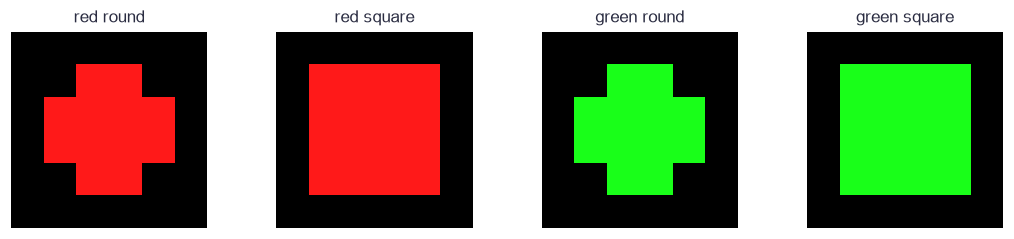

In [3]:
plot_image_text_pairs(concept_images,caption_names)

🔍 **확인** · 색과 모양을 함께 읽어야 네 설명을 구별합니다. 텍스트 ID3=red,4=green,5=round,6=square입니다. PAD=0,BOS=1,EOS=2는 이후 생성에 사용합니다. 정렬 encoder의 고정 두 단어 입력에는 PAD가 없습니다.

In [4]:
def make_shapes(per_class,seed):
    """네 색·모양 조합을 독립 잡음·위치·밝기로 RGB 6×6 이미지로 만듭니다."""
    rng=np.random.default_rng(seed)
    yy,xx=np.mgrid[:6,:6]
    images,labels=[],[]
    colors=np.array([[1.,.1,.1],[.1,1.,.1]])
    for label in range(4):
        for _ in range(per_class):
            cx,cy=2.5+rng.uniform(-.35,.35,size=2)
            radius=1.65
            circle=(xx-cx)**2+(yy-cy)**2<=radius**2
            square=np.maximum(np.abs(xx-cx),np.abs(yy-cy))<=radius
            mask=circle if label%2==0 else square
            image=.03+rng.uniform(.7,1.)*mask[...,None]*colors[label//2]
            image=np.clip(image+rng.normal(0,.02,image.shape),0,1)
            images.append(image)
            labels.append(label)
    return np.array(images),np.array(labels)

In [5]:
def init_alignment(pixels=108,hidden=12,dimension=6,vocabulary=7,seed=50):
    """작은 image MLP와 평균 token embedding·projection을 초기화합니다."""
    rng=np.random.default_rng(seed)
    return {'Wi':rng.normal(0,.25/np.sqrt(pixels),(pixels,hidden)),
            'bi':np.zeros(hidden),'Pi':rng.normal(0,.3,(hidden,dimension)),
            'Et':rng.normal(0,.2,(vocabulary,dimension)),
            'Pt':rng.normal(0,.3,(dimension,dimension))}

In [6]:
def image_features(images,parameters):
    """펼친 RGB 화소를 tanh MLP·projection·정규화에 통과시킵니다."""
    hidden=np.tanh(images@parameters['Wi']+parameters['bi'])
    raw=hidden@parameters['Pi']
    normalized,inverse=normalize_rows(raw)
    return normalized,(images,hidden,normalized,inverse)

In [7]:
def text_features(tokens,parameters):
    """고정 두 token 설명의 평균 embedding을 projection하고 정규화합니다."""
    pooled=parameters['Et'][tokens].mean(axis=1)
    normalized,inverse=normalize_rows(pooled@parameters['Pt'])
    return normalized,(tokens,pooled,normalized,inverse)

In [8]:
def normalize_rows(values,epsilon=1e-6):
    """sqrt(sum(z²)+epsilon)로 나눠 원점에서도 정의되는 표현을 만듭니다."""
    inverse=1/np.sqrt((values**2).sum(axis=1,keepdims=True)+epsilon)
    return values*inverse,inverse

In [9]:
def normalize_backward(upstream,normalized,inverse):
    """epsilon을 포함한 행 정규화의 정확한 미분입니다."""
    return inverse*(upstream-normalized*(upstream*normalized).sum(axis=1,keepdims=True))

In [10]:
projection_x=np.array([[1.,2.]])
projection_w=np.array([[2.,0.],[1.,3.]])
projection_loop=np.zeros((1,2))
for column in range(2):
    for feature in range(2):
        projection_loop[0,column]+=projection_x[0,feature]*projection_w[feature,column]
np.testing.assert_array_equal(projection_loop,[[4.,6.]])  # 검산: 작은 projection 손계산
np.testing.assert_array_equal(projection_loop,projection_x@projection_w)  # 검산: 반복문 = 행렬곱
print('projection 손계산·반복문·벡터화 통과')

projection 손계산·반복문·벡터화 통과


### ✏️ 연습 1 · 공통 폭으로 projection

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

X와 W의 곱을 채우세요.

In [11]:
def exercise_projection(X, W):
    """공통 폭으로 projection의 계산을 완성합니다."""
    ### 구현할 내용: X와 W의 곱을 채우세요.
    raise NotImplementedError
    return projected

In [12]:
def check_projection(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_array_equal(candidate(np.array([[1.,2.]]),np.array([[2.],[3.]])),[[8.]])  # 검산: 2차원 입력을1차원 표현으로
    print("연습 1 통과")

run_check(check_projection, exercise_projection, hint="공통 폭으로 projection의 수식과 축을 확인하세요.")

☐ exercise_projection: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 공통 폭으로 projection의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
projected = X @ W
```

</details>

## 🔑 2. 맞는 이미지·설명 쌍을 양방향으로 고릅니다

**이 절에서 가져갈 것:** 두 방향의 CE와 정규화 미분을 모두 encoder로 전달합니다.

빨간 원 이미지는 빨간 원 설명과, 초록 사각형 이미지는 초록 사각형 설명과 가까워져야 합니다. 같은 배치 N개에서 대각선이 맞는 쌍이 되도록 순서를 맞춥니다.

$$u=\frac{z_i}{\sqrt{\|z_i\|^2+\epsilon}},\quad v=\frac{z_t}{\sqrt{\|z_t\|^2+\epsilon}},\quad S=uv^T/\tau,$$
$$L=\tfrac12[CE(S,\operatorname{arange}(N))+CE(S^T,\operatorname{arange}(N))].$$

u,v:(N,K),S:(N,N),ε=10⁻⁶,τ=.2입니다. CE는 각 행의 정답을 고르고 N행 평균합니다. ε 때문에 norm은 정확히1보다 작을 수 있습니다. 이 내적은 엄밀한 cosine과 ε만큼 다릅니다.

행 softmax R,열 softmax C이면 $dS=(R+C-2I)/(2N)$이고 $du=dSv/\tau$, $dv=dS^Tu/\tau$입니다. 정규화 상류 g에는 $dz=a[g-u\langle g,u\rangle]$, $a=(\|z\|^2+\epsilon)^{-1/2}$를 씁니다. 원점에서도 이 식을 그대로 사용합니다.

image 역전파는 $dP_i=H^Tdz_i$, $dA=(dz_iP_i^T)\odot(1-H^2)$, $dW_i=X^TdA$, $db_i=\sum_ndA$, $dX=dAW_i^T$입니다. text에서는 $dP_t=h_t^Tdz_t$, 각 단어에 $(dz_tP_t^T)/2$를 주고 반복 ID에 더합니다.

In [13]:
image_vector_hand=np.array([[1.,0.],[0.,1.]])
text_vector_hand=np.array([[.8,.2],[.1,.9]])
alignment_score_hand=image_vector_hand@text_vector_hand.T/.2

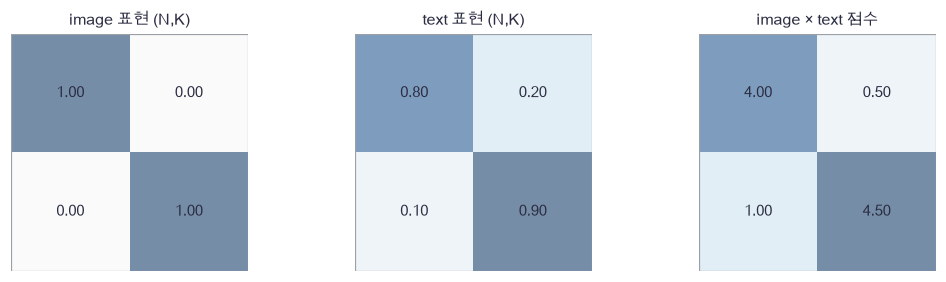

In [14]:
plot_alignment_scores(image_vector_hand,text_vector_hand,alignment_score_hand)

🔍 **확인** · 행은 이미지가 설명을 고르고 열은 설명이 이미지를 고릅니다. 한쪽 softmax만 미분하면 대칭 목적과 다른 gradient가 됩니다. 아래 CE·Adam 함수와 encoder 미분을 본문에 둡니다.

> **코드** · `.T`는 행과 열을 바꿉니다. `np.add.at`은 같은 token이 여러 설명에 나타날 때 gradient를 누적합니다. `np.repeat(...,axis=1)`은 평균한 token 수만큼 미분을 펼칩니다. `numerical_gradient`는 정수 ID가 아닌 실수 파라미터·화소를 중심차분합니다.

In [15]:
def token_cross_entropy(logits, targets, weights):
    """선택한 target만 가중 평균합니다. logprob 전체와 정확한 dlogits를 반환합니다."""
    shifted = logits - logits.max(axis=-1,keepdims=True)
    logprob = shifted - np.log(np.exp(shifted).sum(axis=-1,keepdims=True))
    denominator = weights.sum()
    assert denominator > 0, '손실에 포함할 target이 적어도 하나 필요합니다'
    assert np.all(weights >= 0), '손실 가중치는 음수가 아니어야 합니다'
    rows = np.arange(targets.size)
    selected = logprob.reshape(-1,logits.shape[-1])[rows,targets.ravel()].reshape(targets.shape)
    loss = -np.sum(selected * weights) / denominator
    delta = np.exp(logprob).reshape(-1,logits.shape[-1])
    delta[rows,targets.ravel()] -= 1
    delta *= weights.ravel()[:,None] / denominator
    return float(loss),delta.reshape(logits.shape),logprob

In [16]:
def adam_state(p):
    """모든 학습 배열에 독립인 Adam 상태를 만듭니다."""
    return {'m':{name:np.zeros_like(value) for name,value in p.items()},
            'v':{name:np.zeros_like(value) for name,value in p.items()},'t':0}

In [17]:
def adam_update(p, gradients, state, learning_rate=.01):
    """Adam의 모멘트와 편향 보정으로 지정된 배열만 갱신합니다."""
    state['t'] += 1
    for name in gradients:
        state['m'][name] = .9*state['m'][name] + .1*gradients[name]
        state['v'][name] = .999*state['v'][name] + .001*gradients[name]**2
        first = state['m'][name]/(1-.9**state['t'])
        second = state['v'][name]/(1-.999**state['t'])
        p[name] -= learning_rate*first/(np.sqrt(second)+1e-8)

In [18]:
def image_backward(upstream,cache,parameters):
    """image 표현의 상류 미분을 모든 encoder 배열과 화소로 전달합니다."""
    # 쓰는 것: normalize_backward (앞 절의 정의·실행 셀)
    images,hidden,normalized,inverse=cache
    draw=normalize_backward(upstream,normalized,inverse)
    dhidden=(draw@parameters['Pi'].T)*(1-hidden**2)
    gradients={'Pi':hidden.T@draw,'Wi':images.T@dhidden,'bi':dhidden.sum(axis=0)}
    return gradients,dhidden@parameters['Wi'].T

In [19]:
def text_backward(upstream,cache,parameters):
    """반복된 token의 미분도 np.add.at으로 더합니다."""
    # 쓰는 것: normalize_backward (앞 절의 정의·실행 셀)
    tokens,pooled,normalized,inverse=cache
    draw=normalize_backward(upstream,normalized,inverse)
    dpool=draw@parameters['Pt'].T
    embedding=np.zeros_like(parameters['Et'])
    dtoken=np.repeat(dpool[:,None,:]/tokens.shape[1],tokens.shape[1],axis=1)
    np.add.at(embedding,tokens,dtoken)
    return {'Et':embedding,'Pt':pooled.T@draw}

In [20]:
def symmetric_contrastive(image_vectors,text_vectors,temperature=.2):
    """대각선이 정답인 정방 image/text 쌍의 양방향 InfoNCE입니다."""
    # 쓰는 것: token_cross_entropy (앞 절의 정의·실행 셀)
    scores=image_vectors@text_vectors.T/temperature
    count=len(scores)
    targets=np.arange(count)[None,:]
    weights=np.ones((1,count))
    row_loss,row_delta,_=token_cross_entropy(scores[None,:,:],targets,weights)
    col_loss,col_delta,_=token_cross_entropy(scores.T[None,:,:],targets,weights)
    delta=(row_delta[0]+col_delta[0].T)/2
    return (row_loss+col_loss)/2,delta@text_vectors/temperature,delta.T@image_vectors/temperature,scores

In [21]:
def alignment_loss(images,tokens,parameters):
    """image/text 양쪽 encoder의 전체 목적과 미분입니다."""
    # 쓰는 것: image_features, text_features (앞 절의 정의·실행 셀)
    image_vectors,image_cache=image_features(images,parameters)
    text_vectors,text_cache=text_features(tokens,parameters)
    loss,dimage,dtext,scores=symmetric_contrastive(image_vectors,text_vectors)
    gradients,dx=image_backward(dimage,image_cache,parameters)
    gradients.update(text_backward(dtext,text_cache,parameters))
    return loss,gradients,dx,scores

In [22]:
def check_alignment_gradients():
    """작은 image/text 모델의 모든 배열과 화소 입력을 중심차분합니다."""
    # 쓰는 것: init_alignment, normalize_backward, normalize_rows (앞 절의 정의·실행 셀)
    rng=np.random.default_rng(5010)
    parameters=init_alignment(pixels=4,hidden=3,dimension=2,vocabulary=6)
    images=rng.normal(0,.3,(3,4))
    tokens=np.array([[3,4],[3,5],[4,5]])
    _,gradients,dx,_=alignment_loss(images,tokens,parameters)
    def objective():
        """token ID와 대응 쌍을 고정한 대칭 정렬 목적입니다."""
        return alignment_loss(images,tokens,parameters)[0]
    errors=[]
    for name,value in parameters.items():
        numeric=numerical_gradient(objective,value)
        np.testing.assert_allclose(gradients[name],numeric,atol=5e-7,rtol=4e-4)  # 검산: 모든 encoder 파라미터 미분
        errors.append(np.max(np.abs(gradients[name]-numeric)))
    np.testing.assert_allclose(dx,numerical_gradient(objective,images),atol=5e-7,rtol=4e-4)  # 검산: 연속 화소 입력 미분
    zero=np.zeros((1,2))
    normalized,inverse=normalize_rows(zero)
    np.testing.assert_allclose(normalize_backward(np.ones((1,2)),normalized,inverse),1000.)  # 검산: epsilon 포함 원점 도함수
    return max(errors)

In [23]:
print('정렬 전체 미분 최대절대오차:',check_alignment_gradients())

정렬 전체 미분 최대절대오차: 1.823089093022645e-07


### ✏️ 연습 2 · 양방향 점수 미분

행·열 방향 softmax와 정답행렬로 dS를 채우세요.

In [24]:
def exercise_symmetric(row_probs, col_probs, identity):
    """양방향 점수 미분의 계산을 완성합니다."""
    ### 구현할 내용: 행·열 방향 softmax와 정답행렬로 dS를 채우세요.
    raise NotImplementedError
    return gradient

In [25]:
def check_symmetric(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_allclose(candidate(np.full((2,2),.5),np.full((2,2),.5),np.eye(2)),[[-.25,.25],[.25,-.25]])  # 검산: 두 방향·표본 평균
    print("연습 2 통과")

run_check(check_symmetric, exercise_symmetric, hint="양방향 점수 미분의 수식과 축을 확인하세요.")

☐ exercise_symmetric: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 양방향 점수 미분의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
gradient = (row_probs + col_probs - 2 * identity) / (2 * len(identity))
```

</details>

## 🔑 3. 실제 정렬 학습과 새 이미지 검색을 확인합니다

**이 절에서 가져갈 것:** 학습 배치의 양성 관계와 평가 후보의 의미를 분명히 합니다.

같은 `red round` 설명을 가진 두 이미지가 배치에 있으면 단순 대각선 CE는 다른 하나를 오답으로 밀어냅니다. 이번 실험은 **각 배치에 네 범주에서 한 장씩** 뽑아 설명 중복을 피합니다. 일반 데이터의 여러 양성을 처리한 구현이라고 주장하지 않습니다.

train은 범주당12장(48),valid/test는 각각4장(16)입니다. seed5001/5002/5003으로 위치·밝기·잡음을 독립 생성합니다. 세 split은 같은 네 의미 조합을 포함하며 **새 렌더에 대한 평가**입니다. 학습은250회·배치4·Adam.01·고정τ.2입니다. valid를 기록하고 마지막 모델을 사용하며 test로 설정을 고르지 않습니다.

아래는 설명 ID가 모두 다른 배치와 반복되는 배치에서 의미상 같은 쌍의 표입니다. 대각선만 정답으로 쓰려면 왼쪽 조건이 필요합니다.

In [26]:
unique_labels=np.array([0,1,2,3])
repeated_labels=np.array([0,0,2,3])
unique_positives=(unique_labels[:,None]==unique_labels[None,:]).astype(int)
repeated_positives=(repeated_labels[:,None]==repeated_labels[None,:]).astype(int)

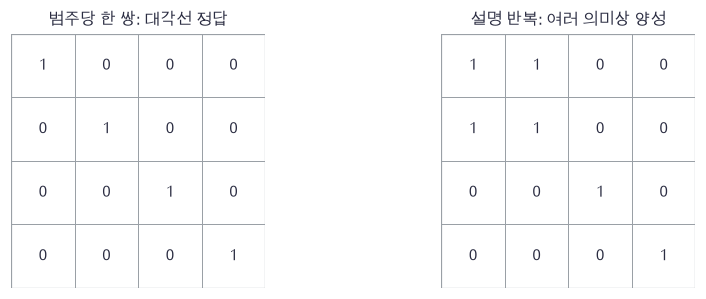

In [27]:
plot_positive_pairs(unique_positives,repeated_positives)

🔍 **확인** · 오른쪽에는 대각선 밖에도 같은 설명의 양성이 있습니다. 여기서는 왼쪽 배치만 학습합니다. 평가는 이미지마다 네 설명 중 정답을 고르는 정확도와, 설명마다16개 test 이미지 중 같은 범주의 이미지를 찾는 정확도를 나눕니다.

> **코드** · `rng.choice(group)`는 해당 범주 이미지 한 장을 고릅니다. `np.flatnonzero(labels==label)`은 그 범주의 행 번호입니다. `argmax(axis=1)`은 이미지별 설명 열을, `argmax(axis=0)`은 설명별 이미지 행을 고릅니다. `reshape(N,-1)`은 RGB 화소축을 펼칩니다.

In [28]:
def retrieval_accuracy(images,labels,captions,parameters):
    """네 설명 후보 검색과 설명에서 같은 범주 이미지 검색을 따로 셉니다."""
    # 쓰는 것: image_features, text_features (앞 절의 정의·실행 셀)
    image_vectors,_=image_features(images,parameters)
    text_vectors,_=text_features(captions,parameters)
    scores=image_vectors@text_vectors.T
    image_to_text=np.mean(scores.argmax(axis=1)==labels)
    text_to_image=np.mean(labels[scores.argmax(axis=0)]==np.arange(len(captions)))
    return image_to_text,text_to_image,scores

In [29]:
def train_alignment(images,labels,captions,valid_images,valid_labels,steps=250):
    """중복 설명이 같은 배치의 거짓 음성이 되지 않도록 범주당 한 장씩 뽑습니다."""
    # 쓰는 것: adam_state, adam_update, alignment_loss, init_alignment (앞 절의 정의·실행 셀)
    parameters=init_alignment()
    state=adam_state(parameters)
    rng=np.random.default_rng(5004)
    groups=[np.flatnonzero(labels==label) for label in range(4)]
    history=[]
    for step in range(steps+1):
        if step%50==0:
            accuracy,_,_=retrieval_accuracy(valid_images,valid_labels,captions,parameters)
            history.append((step,accuracy))
        if step==steps:
            break
        indices=np.array([rng.choice(group) for group in groups])
        _,gradients,_,_=alignment_loss(images[indices],captions,parameters)
        adam_update(parameters,gradients,state,learning_rate=.01)
    return parameters,np.array(history)

In [30]:
# 쓰는 것: caption_tokens, init_alignment, make_shapes (앞 절의 정의·실행 셀)
train_images,train_labels=make_shapes(12,5001)
valid_images,valid_labels=make_shapes(4,5002)
test_images,test_labels=make_shapes(4,5003)
train_x=train_images.reshape(len(train_images),-1)
valid_x=valid_images.reshape(len(valid_images),-1)
test_x=test_images.reshape(len(test_images),-1)
train_fingerprints={image.tobytes() for image in train_images}
assert all(image.tobytes() not in train_fingerprints for image in test_images), 'test 이미지 배열은 train과 겹치지 않아야 합니다'
alignment_initial=init_alignment()
alignment,alignment_history=train_alignment(train_x,train_labels,caption_tokens,valid_x,valid_labels)
alignment_snapshot={name:value.copy() for name,value in alignment.items()}
print('초기 검색:',retrieval_accuracy(test_x,test_labels,caption_tokens,alignment_initial)[:2])
print('학습 후 검색(image→text,text→image):',retrieval_accuracy(test_x,test_labels,caption_tokens,alignment)[:2])

초기 검색: (np.float64(0.125), np.float64(0.25))
학습 후 검색(image→text,text→image): (np.float64(1.0), np.float64(1.0))


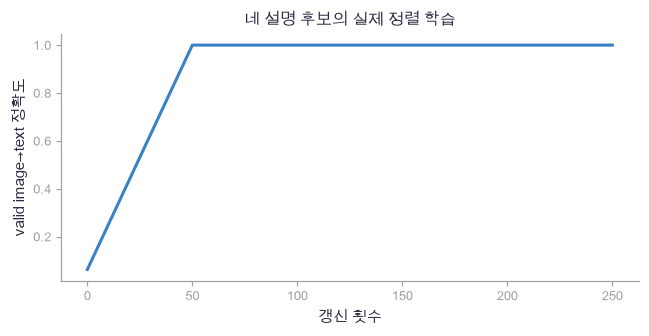

In [31]:
plot_multimodal_learning(alignment_history,'valid image→text 정확도','네 설명 후보의 실제 정렬 학습')

🔍 **확인** · 새 화소 잡음에 대한 검색 결과입니다. 설명 어휘와 네 색·모양 조합은 학습에서 이미 보았습니다. 자연 언어 일반화나 새로운 범주 zero-shot 결과로 해석하지 않습니다.

### ✏️ 연습 3 · 여러 양성 표시

같은 설명 ID의 모든 쌍을 표시하세요.

In [32]:
def exercise_positives(labels):
    """여러 양성 표시의 계산을 완성합니다."""
    ### 구현할 내용: 같은 설명 ID의 모든 쌍을 표시하세요.
    raise NotImplementedError
    return positive

In [33]:
def check_positives(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_array_equal(candidate(np.array([0,0,1])),[[1,1,0],[1,1,0],[0,0,1]])  # 검산: 대각선 밖 같은 설명도 양성
    print("연습 3 통과")

run_check(check_positives, exercise_positives, hint="여러 양성 표시의 수식과 축을 확인하세요.")

☐ exercise_positives: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 여러 양성 표시의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
positive = labels[:, None] == labels[None, :]
```

</details>

## 🔑 4. 이미지 표현을 연속 prefix로 넣어 설명을 학습합니다

**이 절에서 가져갈 것:** 검색용 표현을 decoder 입력으로 연결하고 prefix의 간접 미분을 보존합니다.

검색 모델은 네 설명 중 고를 수 있지만 다음 단어를 내놓지는 않습니다. 학습한 image u:(N,K)를 bridge B:(K,D)로 바꿔 decoder 앞에 **하나의 연속 token**처럼 붙입니다.

$$X_0=uB+P_0,\qquad X_{t+1}=E[I_t]+P_{t+1}.$$

decoder 입력은 `[image,BOS,color,shape]`, target은 텍스트 위치에서 `[color,shape,EOS]`입니다. 전체 shape은 `(N,T+1,D)`입니다. image 위치의 직접 출력 손실은0이지만 뒤 token들이 image에 attention하므로 $dX_0$는 일반적으로0이 아닙니다. $dB=u^TdX_0$, $du=dX_0B^T$입니다. token E는 반복 ID에 누적하고 위치 P는 배치축으로 합칩니다.

45번의 pre-LN causal attention·tanh FFN·최종 LN decoder 전체를 구현합니다. 이번에는 별도 cross-attention 대신 prefix를 causal self-attention에서 읽습니다. image prefix는 항상 유효하고 PAD text key/query는 차단합니다. image도 위치 한 칸을 차지합니다.

정렬 encoder는 고정하고 bridge와 decoder를300회·배치8·Adam.01로 학습합니다. 정렬에 쓴 text encoder는 생성 모델의 token embedding과 별개입니다. [ClipCap](https://arxiv.org/abs/2111.09734)의 image-prefix 연결 발상과 관련되지만, 여기서는 pretrained CLIP/GPT를 쓰지 않는 작은 독립 모델입니다.

In [34]:
feature_hand=np.array([[.8,.2]])
bridge_hand=np.array([[1.,0.,-.5],[0.,2.,.5]])
prefix_hand=feature_hand@bridge_hand

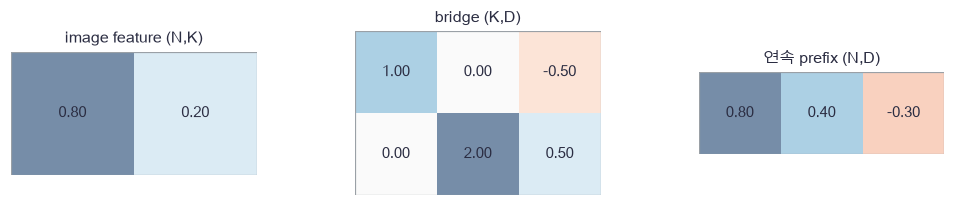

In [35]:
plot_continuous_prefix(feature_hand,bridge_hand,prefix_hand)

🔍 **확인** · image feature는 어휘 ID가 아닙니다. 행렬곱으로 만든 연속 벡터를 위치0에 놓습니다. 따라서 embedding lookup이 아니라 bridge로 미분을 돌려야 합니다. 아래 전체 decoder 정의에서 마지막 projection의 vocabulary V=7,폭D=12,FFN폭F=24입니다.

> **코드** · `np.concatenate(...,axis=1)`은 시간축 앞에 image 위치를 붙입니다. `np.zeros_like(delta[:,:1])`는 직접 loss가 없는 prefix logits 미분을 만듭니다. `.copy()`는 고정 encoder의 보존 검사용 사본입니다. `rng.integers(N,size=8)`은 같은 번호를 허용하는 학습 배치입니다.

In [36]:
def masked_softmax(scores, allowed):
    """마지막 key 축에서 허용한 점수만 정규화합니다. 전부 막힌 행은0입니다."""
    masked = np.where(allowed, scores, -np.inf)
    maximum = masked.max(axis=-1, keepdims=True)
    maximum = np.where(np.isfinite(maximum), maximum, 0.)
    exponential = np.exp(masked - maximum)
    total = exponential.sum(axis=-1, keepdims=True)
    return np.divide(exponential, total, out=np.zeros_like(exponential), where=total > 0)

In [37]:
def layernorm_forward(x, gamma, beta, epsilon=1e-5):
    """각 token의 마지막 D축을 정규화하고 affine 변환합니다."""
    centered = x - x.mean(axis=-1, keepdims=True)
    inverse = 1 / np.sqrt(np.mean(centered**2, axis=-1, keepdims=True) + epsilon)
    normalized = centered * inverse
    return normalized * gamma + beta, (normalized, inverse, gamma)

In [38]:
def layernorm_backward(upstream, cache):
    """epsilon을 포함한 LayerNorm의 입력·gamma·beta 미분을 반환합니다."""
    normalized, inverse, gamma = cache
    weighted = upstream * gamma
    dx = inverse * (weighted - weighted.mean(axis=-1, keepdims=True)
                    - normalized * (weighted * normalized).mean(axis=-1, keepdims=True))
    axes = tuple(range(upstream.ndim - 1))
    return dx, np.sum(upstream * normalized, axis=axes), np.sum(upstream, axis=axes)

In [39]:
def attention_forward(x, valid, p, causal=True):
    """한 head self-attention. x:(N,T,D), valid:(N,T); query/key padding을 모두 막습니다."""
    q, k, v = x @ p['Wq'], x @ p['Wk'], x @ p['Wv']
    scores = q @ k.swapaxes(-1,-2) / np.sqrt(x.shape[-1])
    allowed = valid[:,:,None] & valid[:,None,:]
    if causal:
        allowed = allowed & np.tril(np.ones((x.shape[1],x.shape[1]),dtype=bool))[None,:,:]
    probabilities = masked_softmax(scores, allowed)
    mixed = probabilities @ v
    return mixed @ p['Wo'], (x,q,k,v,probabilities,mixed)

In [40]:
def attention_backward(upstream, cache, p):
    """attention의 값 경로와 Q/K 점수 경로를 모두 누적합니다."""
    x,q,k,v,probabilities,mixed = cache
    width = x.shape[-1]
    delta = upstream @ p['Wo'].T
    dp = delta @ v.swapaxes(-1,-2)
    dv = probabilities.swapaxes(-1,-2) @ delta
    ds = probabilities * (dp - np.sum(dp * probabilities, axis=-1, keepdims=True))
    dq = (ds @ k) / np.sqrt(width)
    dk = (ds.swapaxes(-1,-2) @ q) / np.sqrt(width)
    flat = x.reshape(-1,width)
    gradients = {'Wo': mixed.reshape(-1,width).T @ upstream.reshape(-1,width),
                 'Wq': flat.T @ dq.reshape(-1,width), 'Wk': flat.T @ dk.reshape(-1,width),
                 'Wv': flat.T @ dv.reshape(-1,width)}
    dx = dq @ p['Wq'].T + dk @ p['Wk'].T + dv @ p['Wv'].T
    return dx, gradients

In [41]:
def init_decoder(vocabulary_size, width=12, hidden=24, max_length=32, seed=45, tied=False):
    """한 pre-LN decoder block과 최종 LN·head를 만듭니다. 모든 배열은 float64입니다."""
    rng = np.random.default_rng(seed)
    p = {'E': rng.normal(0,.15,(vocabulary_size,width)),
         'P': rng.normal(0,.08,(max_length,width))}
    for layer in ['1','2','f']:
        p['g'+layer] = np.ones(width)
        p['b'+layer] = np.zeros(width)
    for name in ['Wq','Wk','Wv','Wo']:
        p[name] = rng.normal(0,.25/np.sqrt(width),(width,width))
    p['W1'] = rng.normal(0,.5/np.sqrt(width),(width,hidden))
    p['c1'] = np.zeros(hidden)
    p['W2'] = rng.normal(0,.5/np.sqrt(hidden),(hidden,width))
    p['c2'] = np.zeros(width)
    if not tied:
        p['head'] = rng.normal(0,.3/np.sqrt(width),(width,vocabulary_size))
    p['bias'] = np.zeros(vocabulary_size)
    return p

In [42]:
def decoder_from_embeddings(x, valid, p, tied=False, causal=True):
    """연속 embedding 입력에서 LN→attention→잔차→LN→FFN→잔차→LN→head입니다."""
    # 쓰는 것: layernorm_forward (앞 절의 정의·실행 셀)
    first, cache1 = layernorm_forward(x,p['g1'],p['b1'])
    attended, attention_cache = attention_forward(first,valid,p,causal)
    residual = x + attended
    second, cache2 = layernorm_forward(residual,p['g2'],p['b2'])
    activation = np.tanh(second @ p['W1'] + p['c1'])
    hidden = residual + activation @ p['W2'] + p['c2']
    final, cachef = layernorm_forward(hidden,p['gf'],p['bf'])
    head = p['E'].T if tied else p['head']
    logits = final @ head + p['bias']
    return logits,(cache1,attention_cache,cache2,second,activation,cachef,final)

In [43]:
def decoder_feature_backward(dlogits, cache, p, tied=False):
    """연속 입력과 모든 block/head 배열을 미분합니다. tied이면 출력 E 경로도 더합니다."""
    # 쓰는 것: layernorm_backward (앞 절의 정의·실행 셀)
    # 1) head와 최종 정규화를 거슬러 갑니다.
    cache1,attention_cache,cache2,second,activation,cachef,final = cache
    width = final.shape[-1]
    gradients = {name:np.zeros_like(value) for name,value in p.items()}
    head_gradient = final.reshape(-1,width).T @ dlogits.reshape(-1,dlogits.shape[-1])
    if tied:
        gradients['E'] += head_gradient.T
        delta = dlogits @ p['E']
    else:
        gradients['head'] = head_gradient
        delta = dlogits @ p['head'].T
    gradients['bias'] = dlogits.sum(axis=(0,1))
    dh,gradients['gf'],gradients['bf'] = layernorm_backward(delta,cachef)
    # 2) FFN 경로와 직접 잔차 경로를 합칩니다.
    gradients['W2'] = activation.reshape(-1,activation.shape[-1]).T @ dh.reshape(-1,width)
    gradients['c2'] = dh.sum(axis=(0,1))
    da = (dh @ p['W2'].T) * (1-activation**2)
    gradients['W1'] = second.reshape(-1,width).T @ da.reshape(-1,da.shape[-1])
    gradients['c1'] = da.sum(axis=(0,1))
    dr,gradients['g2'],gradients['b2'] = layernorm_backward(da @ p['W1'].T,cache2)
    dr += dh
    # 3) attention의 모든 경로와 첫 잔차를 합칩니다.
    du,attention_gradients = attention_backward(dr,attention_cache,p)
    gradients.update(attention_gradients)
    dx,gradients['g1'],gradients['b1'] = layernorm_backward(du,cache1)
    return dx + dr, gradients

In [44]:
def language_batch(documents, pad=0, bos=1, eos=2):
    """정수 문서 목록을 BOS 입력·EOS 타깃으로 이동하고 오른쪽 PAD를 채웁니다."""
    length = max(len(document)+1 for document in documents)
    ids = np.full((len(documents),length),pad,dtype=int)
    targets = np.full_like(ids,pad)
    valid = np.zeros_like(ids,dtype=bool)
    for index,document in enumerate(documents):
        count = len(document)+1
        ids[index,:count] = [bos]+list(document)
        targets[index,:count] = list(document)+[eos]
        valid[index,:count] = True
    return ids,targets,valid

In [45]:
def conditional_forward(features,ids,valid,parameters):
    """image feature를 한 연속 prefix token으로 붙인 causal decoder입니다."""
    count,length=ids.shape
    assert length+1<=len(parameters['P']), 'image prefix도 위치 공간 하나를 사용합니다'
    prefix=features@parameters['bridge']+parameters['P'][0]
    words=(parameters['E'][ids]+parameters['P'][1:length+1])*valid[:,:,None]
    inputs=np.concatenate([prefix[:,None,:],words],axis=1)
    allowed=np.concatenate([np.ones((count,1),dtype=bool),valid],axis=1)
    logits,cache=decoder_from_embeddings(inputs,allowed,parameters)
    return logits[:,1:],(features,ids,valid,cache)

In [46]:
def conditional_backward(delta,cache,parameters):
    """prefix·text 두 경로의 전체 decoder/bridge 미분과 조건 입력 미분입니다."""
    features,ids,valid,model_cache=cache
    expanded=np.concatenate([np.zeros_like(delta[:,:1]),delta],axis=1)
    dx,gradients=decoder_feature_backward(expanded,model_cache,parameters)
    dx[:,1:]*=valid[:,:,None]
    np.add.at(gradients['E'],ids,dx[:,1:])
    gradients['P'][:dx.shape[1]]+=dx.sum(axis=0)
    gradients['bridge']=features.T@dx[:,0]
    dfeatures=dx[:,0]@parameters['bridge'].T
    return gradients,dfeatures

In [47]:
def conditional_loss(features,batch,parameters):
    """이미지 위치를 제외하고 color·shape·EOS의 평균 CE를 계산합니다."""
    # 쓰는 것: token_cross_entropy (앞 절의 정의·실행 셀)
    logits,cache=conditional_forward(features,batch[0],batch[2],parameters)
    loss,delta,log_probs=token_cross_entropy(logits,batch[1],batch[2])
    gradients,dfeatures=conditional_backward(delta,cache,parameters)
    return loss,gradients,dfeatures,log_probs

In [48]:
def train_caption_decoder(train_features,train_batch,valid_features,valid_batch,steps=300):
    """고정 정렬 표현에서 bridge와 decoder를 처음부터 함께 학습합니다."""
    # 쓰는 것: adam_state, adam_update, init_decoder (앞 절의 정의·실행 셀)
    parameters=init_decoder(7,width=12,hidden=24,max_length=8,seed=5005)
    parameters['bridge']=np.random.default_rng(5006).normal(0,.3,(train_features.shape[1],12))
    state=adam_state(parameters)
    rng=np.random.default_rng(5007)
    history=[]
    for step in range(steps+1):
        if step%100==0:
            loss,_,_,_=conditional_loss(valid_features,valid_batch,parameters)
            history.append((step,loss))
        if step==steps:
            break
        indices=rng.integers(len(train_features),size=8)
        batch=tuple(value[indices] for value in train_batch)
        _,gradients,_,_=conditional_loss(train_features[indices],batch,parameters)
        adam_update(parameters,gradients,state,learning_rate=.01)
    return parameters,np.array(history)

In [49]:
def check_conditional_gradients():
    """연속 image 조건과 모든 decoder·bridge 배열을 중심차분합니다."""
    # 쓰는 것: init_decoder, language_batch (앞 절의 정의·실행 셀)
    rng=np.random.default_rng(5011)
    parameters=init_decoder(7,width=3,hidden=4,max_length=6,seed=5011)
    parameters['bridge']=rng.normal(0,.2,(2,3))
    features=rng.normal(0,.3,(2,2))
    batch=language_batch([[3,5],[4]])
    _,gradients,dfeatures,_=conditional_loss(features,batch,parameters)
    def objective():
        """고정 caption에서 연속 조건을 사용하는 token CE입니다."""
        return conditional_loss(features,batch,parameters)[0]
    errors=[]
    for name,value in parameters.items():
        numeric=numerical_gradient(objective,value)
        np.testing.assert_allclose(gradients[name],numeric,atol=5e-7,rtol=4e-4)  # 검산: 전체 decoder와 bridge 미분
        errors.append(np.max(np.abs(gradients[name]-numeric)))
    np.testing.assert_allclose(dfeatures,numerical_gradient(objective,features),atol=5e-7,rtol=4e-4)  # 검산: 조건 입력 미분
    assert np.max(np.abs(dfeatures))>1e-8, 'image prefix는 뒤 답변의 간접 미분을 받아야 합니다'
    return max(errors)

In [50]:
# 쓰는 것: alignment, caption_tokens, image_features, language_batch, test_labels, test_x, train_labels, train_x, valid_labels, valid_x (앞 절의 정의·실행 셀)
print('조건 decoder 전체 미분 최대절대오차:',check_conditional_gradients())
train_features,_=image_features(train_x,alignment)
valid_features,_=image_features(valid_x,alignment)
test_features,_=image_features(test_x,alignment)
train_batch=language_batch(caption_tokens[train_labels].tolist())
valid_batch=language_batch(caption_tokens[valid_labels].tolist())
test_batch=language_batch(caption_tokens[test_labels].tolist())
caption_model,caption_history=train_caption_decoder(train_features,train_batch,valid_features,valid_batch)
print('test 답변+EOS NLL:',conditional_loss(test_features,test_batch,caption_model)[0])

조건 decoder 전체 미분 최대절대오차: 2.8542285028521075e-10


test 답변+EOS NLL: 0.006674739738730998


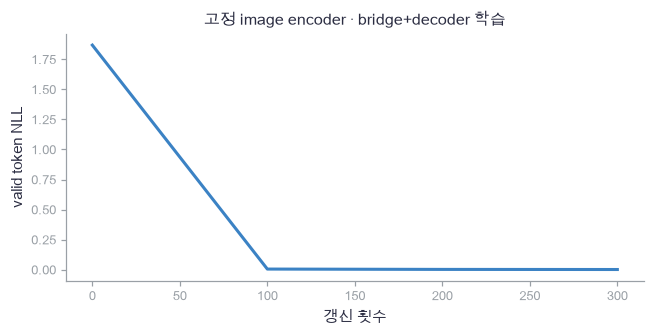

In [51]:
plot_multimodal_learning(caption_history,'valid token NLL','고정 image encoder · bridge+decoder 학습')

🔍 **확인** · 정렬 목적은 배치의 이미지·텍스트 대응을 구별하고, 생성 목적은 문맥에서 다음 token을 맞힙니다. 두 loss의 숫자를 직접 성능 순위로 비교하지 않습니다. 학습한 encoder 배열은 끝에서 완전히 같은지 검사합니다.

In [52]:
def generate_caption(feature,parameters,max_new_tokens=4):
    """이미지 조건과 BOS만으로 설명을 생성하고 EOS/상한 종료를 반환합니다."""
    # 쓰는 것: conditional_forward (앞 절의 정의·실행 셀)
    ids=[1]
    reason='token_limit'
    for _ in range(max_new_tokens):
        if len(ids)+1>len(parameters['P']):
            reason='position_limit'
            break
        inputs=np.array([ids])
        logits,_=conditional_forward(feature[None,:],inputs,np.ones_like(inputs,dtype=bool),parameters)
        scores=logits[0,-1].copy()
        scores[[0,1]]=-np.inf
        token=int(np.argmax(scores))
        ids.append(token)
        if token==2:
            reason='EOS'
            break
    return ids[1:],reason

### ✏️ 연습 4 · bridge 기울기

image feature와 prefix 상류 미분으로 dB를 채우세요.

In [53]:
def exercise_bridgegrad(features, prefix_gradient):
    """bridge 기울기의 계산을 완성합니다."""
    ### 구현할 내용: image feature와 prefix 상류 미분으로 dB를 채우세요.
    raise NotImplementedError
    return gradient

In [54]:
def check_bridgegrad(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_array_equal(candidate(np.array([[1.,2.]]),np.array([[3.,4.]])),[[3.,4.],[6.,8.]])  # 검산: 조건·prefix 외적
    print("연습 4 통과")

run_check(check_bridgegrad, exercise_bridgegrad, hint="bridge 기울기의 수식과 축을 확인하세요.")

☐ exercise_bridgegrad: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: bridge 기울기의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
gradient = features.T @ prefix_gradient
```

</details>

## 🔑 5. 조건을 교환하고 한 token씩 직접 생성합니다

**이 절에서 가져갈 것:** teacher forcing 정확도와 정답 없는 실제 생성, 검색과 조건 교환을 나눠 평가합니다.

이미지를 주고 BOS만 넣은 뒤 color→shape→EOS를 모델이 고르게 합니다. PAD/BOS를 출력 후보에서 제외하고 최대4token 또는 EOS에서 멈춥니다. 성공은 **두 단어와 EOS까지 전체 일치**입니다. 상한 종료도 분모16에 포함합니다.

네 대표 test 이미지의 조건을 한 범주씩 바꿔 같은 decoder에 넣습니다. 모델이 이미지 조건을 사용한다면 생성이 함께 바뀔 수 있습니다. 또 같은 장면의 text encoder 표현을 bridge에 넣어 봅니다. 정렬은 두 표현을 가깝게 하려 하지만 동일하게 만들지는 않으므로 **text 조건으로 바꾸면 항상 생성도 같다는 보장은 없습니다.** 이 교환은 별도 진단입니다.

> **용어** · **greedy 생성**은 매번 가장 큰 다음 token 점수를 고릅니다. **teacher forcing 평가**는 정답 앞부분을 읽고 다음 token을 맞히는 평가입니다. 아래 자유 생성에서는 정답 앞부분을 넣지 않습니다.

In [55]:
# 쓰는 것: caption_model, test_features (앞 절의 정의·실행 셀)
show_indices=np.array([0,4,8,12])
swapped_indices=np.array([4,8,12,0])
shown_answers=[generate_caption(test_features[i],caption_model)[0] for i in show_indices]
swapped_answers=[generate_caption(test_features[i],caption_model)[0] for i in swapped_indices]
token_names={0:'PAD',1:'BOS',2:'EOS',3:'red',4:'green',5:'round',6:'square'}
shown_text=[' '.join(token_names[token] for token in answer) for answer in shown_answers]
swapped_text=[' '.join(token_names[token] for token in answer) for answer in swapped_answers]

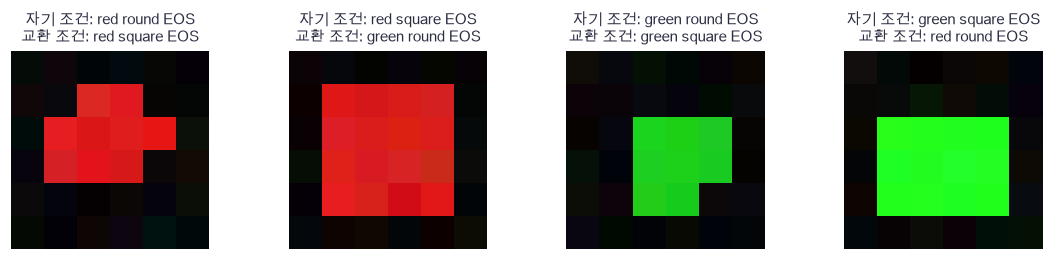

In [56]:
plot_condition_swap(test_images[show_indices],shown_text,swapped_text)

🔍 **확인** · 각 칸의 이미지는 원래 조건입니다. 둘째 줄 생성에는 다음 범주 이미지의 feature를 대신 넣었습니다. 따라서 원래 이미지 설명과 달라지는 것이 기대되는 변화입니다. 아래 수치는 전체16장의 실제 생성과 네 text 조건의 교환 결과를 따로 셉니다.

In [57]:
# 쓰는 것: alignment, alignment_snapshot, caption_model, caption_names, caption_tokens, conditional_loss, generate_caption, test_batch, test_features, test_labels, text_features (앞 절의 정의·실행 셀)
generated_results=[generate_caption(feature,caption_model) for feature in test_features]
exact=np.mean([answer==list(caption_tokens[label])+[2] for (answer,reason),label in zip(generated_results,test_labels)])
eos_rate=np.mean([reason=='EOS' for answer,reason in generated_results])
_,_,_,test_log_probs=conditional_loss(test_features,test_batch,caption_model)
token_accuracy=np.mean(test_log_probs.argmax(axis=-1)[test_batch[2]]==test_batch[1][test_batch[2]])
print('teacher forcing token 정확도:',token_accuracy,'free 전체 일치:',exact,'EOS 종료:',eos_rate)
text_conditions,_=text_features(caption_tokens,alignment)
for name,feature in zip(caption_names,text_conditions):
    print('text 조건',name,'→',generate_caption(feature,caption_model))
for name in alignment:
    np.testing.assert_array_equal(alignment[name],alignment_snapshot[name])  # 검산: 생성 학습 후 정렬 encoder 완전 불변
print('고정 encoder 검산 통과')

teacher forcing token 정확도: 1.0 free 전체 일치: 1.0 EOS 종료: 1.0
text 조건 red round → ([3, 5, 2], 'EOS')
text 조건 red square → ([3, 6, 2], 'EOS')
text 조건 green round → ([4, 5, 2], 'EOS')
text 조건 green square → ([4, 6, 2], 'EOS')
고정 encoder 검산 통과


In [58]:
def check_condition_boundaries():
    """PAD 폭·값 불변, 미래 차단과 강제 EOS·미종료 경계를 확인합니다."""
    # 쓰는 것: conditional_forward, generate_caption, init_decoder (앞 절의 정의·실행 셀)
    parameters=init_decoder(7,width=3,hidden=4,max_length=8,seed=5012)
    parameters['bridge']=np.ones((2,3))*.2
    feature=np.array([[.2,.8]])
    inputs=np.array([[1,3,5]])
    valid=np.ones_like(inputs,dtype=bool)
    original,_=conditional_forward(feature,inputs,valid,parameters)
    changed=inputs.copy()
    changed[0,2]=6
    future,_=conditional_forward(feature,changed,valid,parameters)
    np.testing.assert_allclose(original[:,:2],future[:,:2],atol=1e-12)  # 검산: 미래 token은 과거 logits에 영향 없음
    padded=np.array([[1,3,5,6,4]])
    padded_valid=np.array([[1,1,1,0,0]],dtype=bool)
    padded_logits,_=conditional_forward(feature,padded,padded_valid,parameters)
    np.testing.assert_allclose(original,padded_logits[:,:3],atol=1e-12)  # 검산: PAD 폭·값 변경 불변
    parameters['head'][:]=0
    parameters['bias'][:]=0
    parameters['bias'][2]=1
    assert generate_caption(feature[0],parameters)==([2],'EOS'), '즉시 EOS도 실제 종료입니다'
    parameters['bias'][2]=0
    parameters['bias'][3]=1
    assert generate_caption(feature[0],parameters,max_new_tokens=2)==([3,3],'token_limit'), '미종료도 상한으로 반환합니다'
    print('causal·PAD·EOS·상한 검산 통과')

In [59]:
check_condition_boundaries()

causal·PAD·EOS·상한 검산 통과


### ✏️ 연습 5 · 조건 교환 후 변화

두 조건의 생성 답변이 다른지 채우세요.

In [60]:
def exercise_swap(original, swapped):
    """조건 교환 후 변화의 계산을 완성합니다."""
    ### 구현할 내용: 두 조건의 생성 답변이 다른지 채우세요.
    raise NotImplementedError
    return changed

In [61]:
def check_swap(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    assert candidate([3,5,2],[4,5,2]), '색 token 변화도 조건 반응입니다'
    assert not candidate([3,5,2],[3,5,2]), '같은 생성은 변화가 아닙니다'
    print("연습 5 통과")

run_check(check_swap, exercise_swap, hint="조건 교환 후 변화의 수식과 축을 확인하세요.")

☐ exercise_swap: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 조건 교환 후 변화의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
changed = original != swapped
```

</details>

## ✏️ 끝 연습 A–D

정규화·검색 축·반복 token·생성 분모를 독립적으로 확인합니다.

### ✏️ 연습 A · epsilon 정규화

행별 norm으로 나눈 표현을 채우세요.

In [62]:
def exercise_norm(values, epsilon):
    """epsilon 정규화의 계산을 완성합니다."""
    ### 구현할 내용: 행별 norm으로 나눈 표현을 채우세요.
    raise NotImplementedError
    return normalized

In [63]:
def check_norm(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_allclose(candidate(np.array([[0.,0.],[3.,4.]]),0.01),[[0.,0.],[3/np.sqrt(25.01),4/np.sqrt(25.01)]])  # 검산: 원점과 일반 행
    print("연습 A 통과")

run_check(check_norm, exercise_norm, hint="epsilon 정규화의 수식과 축을 확인하세요.")

☐ exercise_norm: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: epsilon 정규화의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
normalized = values / np.sqrt((values ** 2).sum(axis=1, keepdims=True) + epsilon)
```

</details>

### ✏️ 연습 B · 이미지에서 설명 찾기

각 이미지 행의 최대 점수 설명 번호를 채우세요.

In [64]:
def exercise_retrieve(scores):
    """이미지에서 설명 찾기의 계산을 완성합니다."""
    ### 구현할 내용: 각 이미지 행의 최대 점수 설명 번호를 채우세요.
    raise NotImplementedError
    return indices

In [65]:
def check_retrieve(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_array_equal(candidate(np.array([[.1,.9],[.8,.2]])),[1,0])  # 검산: 행마다 설명 열 선택
    print("연습 B 통과")

run_check(check_retrieve, exercise_retrieve, hint="이미지에서 설명 찾기의 수식과 축을 확인하세요.")

☐ exercise_retrieve: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 이미지에서 설명 찾기의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
indices = scores.argmax(axis=1)
```

</details>

### ✏️ 연습 C · 평균 token의 상류 미분

두 단어 평균의 각 token 미분을 채우세요.

In [66]:
def exercise_meanback(upstream):
    """평균 token의 상류 미분의 계산을 완성합니다."""
    ### 구현할 내용: 두 단어 평균의 각 token 미분을 채우세요.
    raise NotImplementedError
    return per_token

In [67]:
def check_meanback(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_array_equal(candidate(np.array([[2.,4.]])),[[1.,2.]])  # 검산: 평균 분모2
    print("연습 C 통과")

run_check(check_meanback, exercise_meanback, hint="평균 token의 상류 미분의 수식과 축을 확인하세요.")

☐ exercise_meanback: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 평균 token의 상류 미분의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
per_token = upstream / 2
```

</details>

### ✏️ 연습 D · 전체 생성 성공률

성공 여부를 모든 이미지에 대해 평균하세요.

In [68]:
def exercise_success(successes):
    """전체 생성 성공률의 계산을 완성합니다."""
    ### 구현할 내용: 성공 여부를 모든 이미지에 대해 평균하세요.
    raise NotImplementedError
    return rate

In [69]:
def check_success(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_allclose(candidate(np.array([1,0,1,0])),.5)  # 검산: 미종료·오답도 분모에 포함
    print("연습 D 통과")

run_check(check_success, exercise_success, hint="전체 생성 성공률의 수식과 축을 확인하세요.")

☐ exercise_success: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 전체 생성 성공률의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
rate = np.mean(successes)
```

</details>

## ✏️ 준비도 확인

- **설명:** 검색 목적만 학습한 모델이 바로 문장을 생성하지는 않는 이유를 말할 수 있나요?
- **수식:** 대칭 InfoNCE의 두 softmax 축과 image-prefix bridge 미분의 shape를 쓸 수 있나요?
- **구현:** 반복 text token과 image prefix의 간접 attention 미분을 보존할 수 있나요?
- **변형 검산:** 조건 이미지·text 표현·PAD 폭·미래 token·EOS 상한을 바꿔 기대 불변/변화를 확인할 수 있나요?

## 📎 참고와 다음 연결

[CLIP 원문](https://arxiv.org/abs/2103.00020)은 image/text 대조 정렬을, [ClipCap 원문](https://arxiv.org/abs/2111.09734)은 image 표현을 언어 모델 prefix로 잇는 방법을 보여 줍니다. 여기서는 작은 MLP와 단일 decoder를 처음부터 학습했습니다. 실제 CLIP의 대규모 encoder·데이터나 ClipCap의 pretrained 조합을 재현한 것이 아닙니다.

[20 encoder–decoder](../03_구조조합/20_sequence_encoder_decoder.ipynb)의 cross-attention은 별도 조건 sequence를 읽는 또 다른 연결입니다. 현재 prefix 방식은 그 계산을 단순화한 선택입니다. 이후 강화학습 경로에서는 정답 token CE 대신 행동 결과의 보상으로 정책을 갱신하는 차이를 이어갑니다.